In [1]:
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

def parse_log_file(file_path):
    results = {}

    # Updated patterns to capture optional negative sign
    val_pattern = re.compile(r"Step: (\d+), Validation Loss: (-?[\d.]+)")
    train_pattern = re.compile(r"Saving model checkpoint at step (\d+)\. Average loss since last checkpoint: (-?[\d.]+)")

    with open(file_path, 'r') as f:
        for line in f:
            val_match = val_pattern.search(line)
            if val_match:
                step = int(val_match.group(1))
                loss = float(val_match.group(2))
                if step not in results:
                    results[step] = {}
                results[step]['validation_loss'] = loss
                continue

            train_match = train_pattern.search(line)
            if train_match:
                step = int(train_match.group(1))
                loss = float(train_match.group(2))
                if step not in results:
                    results[step] = {}
                results[step]['training_loss'] = loss

    df = pd.DataFrame.from_dict(results, orient='index')
    df.index.name = 'step'
    df.sort_index(inplace=True)
    
    return df


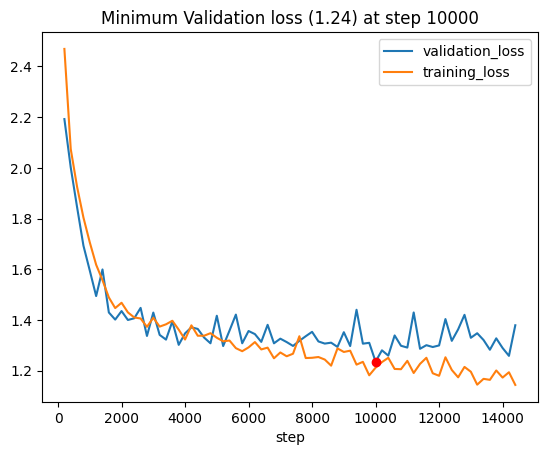

In [4]:
run_dir = "/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled_dams/swot_vae_20260527_154025"
df = parse_log_file(Path(run_dir) / 'training.log')
df.plot()
# plt.xlim([0,1000])

x_min = df['validation_loss'].idxmin()
y_min = df['validation_loss'].min()

plt.plot(x_min, y_min, 'ro')
plt.title(f"Minimum Validation loss ({y_min:0.2f}) at step {x_min}")

plt.show()